# PDE 3 notebook

## Crank Nicolson method for diffusion equation

Starting with the diffusion equation:
$$
\frac{\partial \phi}{\partial t} = D\nabla^2\phi
$$
we get the following equation:
$$
\phi_{i,j+1} - \frac{Dh}{2a^2}\left[\phi_{i+1,j+1}-2\phi_{i,j+1}+\phi_{i-1,j+1}\right] = \phi_{i,j} + \frac{Dh}{2a^2}\left[\phi_{i+1,j}-2\phi_{i,j}+\phi_{i-1,j}\right]
$$
where:
- $i$ is the index in the space direction
- $j$ is the index in the time direction
- $h$ is the time step
- $D$ is the diffusion constant
- $a$ is the spatial step

Using $\lambda = Dh/2a^2$, we can rewrite the equation above as a matrix equation:
$$
\begin{pmatrix}
1+2\lambda & -\lambda & 0 & 0 & 0 & \ldots \\
-\lambda & 1+2\lambda & -\lambda & 0 & 0 & \ldots \\
0 & -\lambda & 1+2\lambda & -\lambda & 0 & \ldots \\
\vdots & \vdots & \vdots & \vdots & \vdots & \ddots \\
\vdots & \vdots & \vdots & \vdots & \vdots & \ddots \\
\end{pmatrix}
\begin{pmatrix}
\phi_{0,j+1} \\ \phi_{1,j+1} \\ \phi_{2, j+1} \\ \vdots \\ \phi_{N-1, j+1}
\end{pmatrix}
= 
\begin{pmatrix}
A_0 \\ A_1 \\ A_2 \\ \vdots \\ A_{N-1}
\end{pmatrix}
$$

with 
$$
A_i = \phi_{i,j} + \frac{Dh}{2a^2}\left[\phi_{i+1,j} - 2\phi_{i,j} + \phi_{i-1, j}\right]
$$

We have to fix the boundary conditions. Assume Dirichlet conditions $\phi_{0,j} = B$ and $\phi_{N-1,j} = C$ for all $j$. If we label the matrix equation above as:
$$
M \vec{\phi} = \vec{A}
$$
applying the B.C.'s mean:
- $M_{0,0} = 1$
- $M_{0,1} = 0$
- $M_{N-1,N-1} = 1$
- $M_{N-1, N-2} = 0$
- $\vec{A}_0 = B$
- $\vec{A}_{N-1} = C$

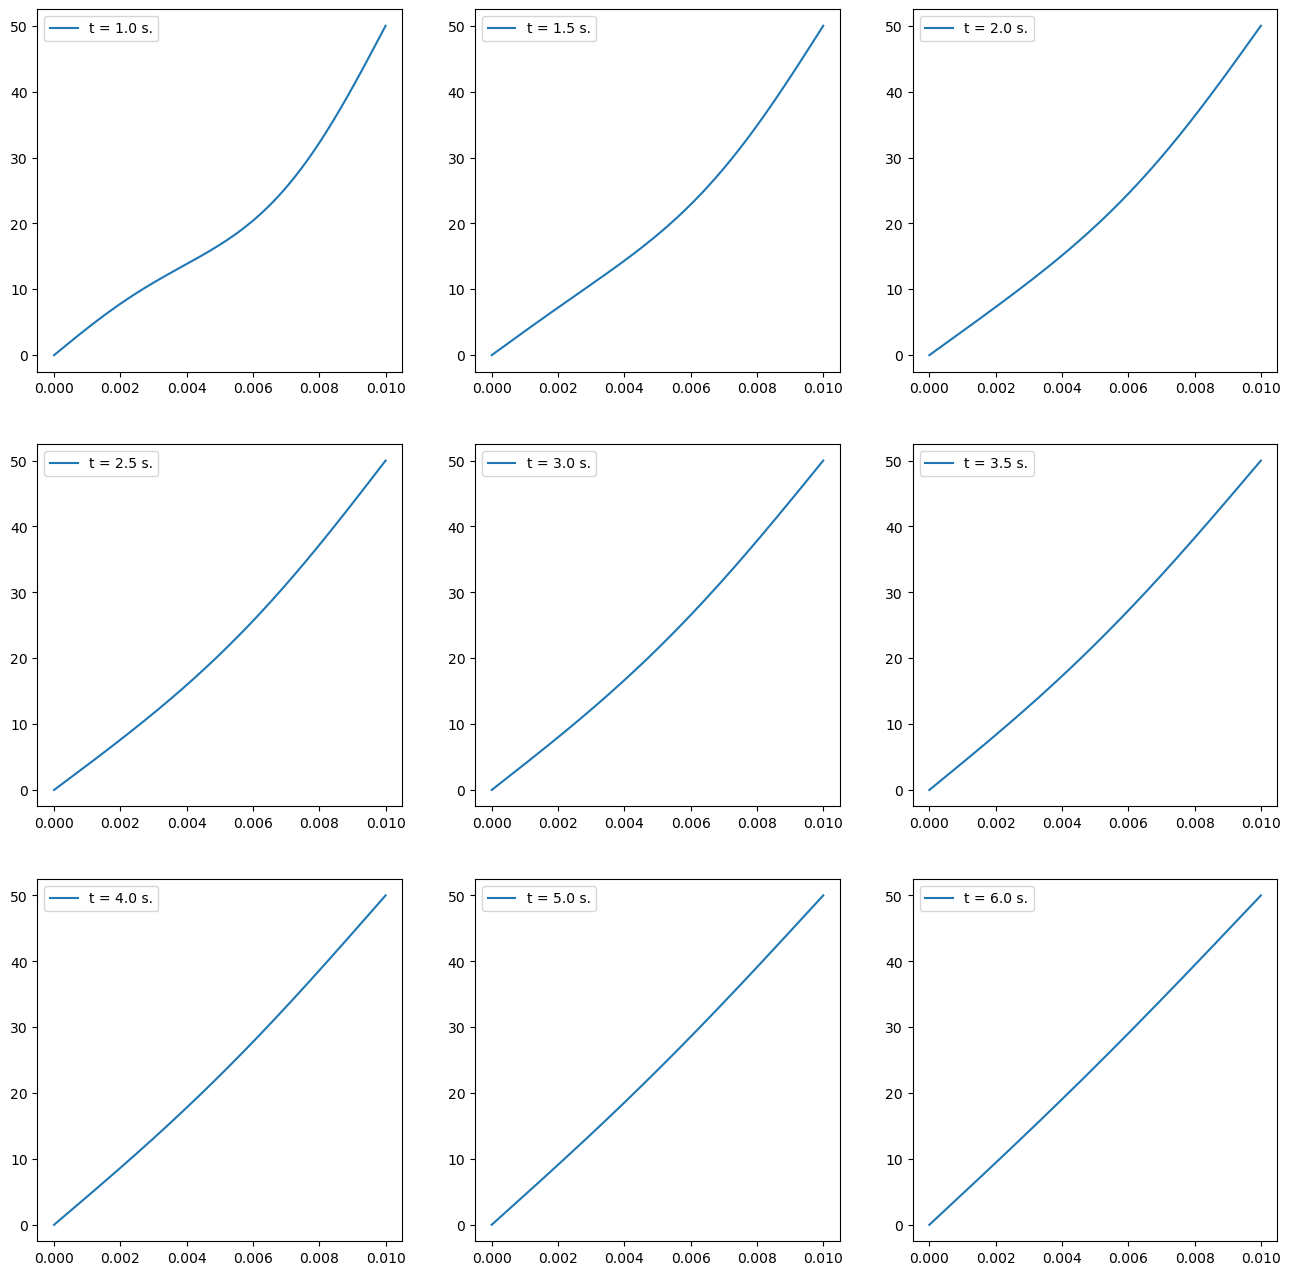

In [7]:
import numpy as np 
import matplotlib.pyplot as plt 
import scipy.linalg as sla 

# Constants
L = 0.01
D = 4.25e-6
N = 200
a = L/N
h = 1e-4 
T1 = 0.0
Tmid = 15.0    # Temperature of the rod before making contact
T2 = 50.0 
t_max = 6.0
epsilon = h/1000.

# Create temperature array with init temp at Tmid degC
T = Tmid*np.ones(N, dtype="float")
# Fix the end of the temperature array
T[0] = T1
T[-1] = T2 
A = np.zeros(N, dtype="float")
A[0] = T1
A[-1] = T2

# x axis
x = np.linspace(0, L, num=N)

# Constants for the loop
t = 0.0
c = h*D/2.0/a**2

# Create diagonals for system matrix
upper_diag = -c*np.ones(N-1)
lower_diag = -c*np.ones(N-1)
diagonal = (1+2*c)*np.ones(N)

# Fix B.C.
upper_diag[0] = 0
lower_diag[-1] = 0
diagonal[0] = 1
diagonal[-1] = 1

# Create system matrix
M = np.diag(diagonal) + np.diag(upper_diag, k=1) + np.diag(lower_diag, k=-1)

# Calculate LUP decomposition
lu, piv = sla.lu_factor(M)


times_pict = [1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 5.0, 6.0]
counter_pict = 0

fig2, axes2 = plt.subplots(3,3, figsize=(16,16))

# Find the solutions
while t < t_max:
    for i in range(1,N-1):
        A[i] = T[i] + c*(T[i+1]-2*T[i]+T[i-1])

    T = sla.lu_solve((lu, piv), A)
    
    if counter_pict<len(times_pict):
        if np.abs(t-times_pict[counter_pict])<epsilon:
            i = counter_pict // 3
            j = counter_pict % 3
            axes2[i,j].plot(x, T, label=f"t = {times_pict[counter_pict]} s.")
            axes2[i,j].legend(loc='upper left')
            counter_pict += 1

    t += h

plt.show()

The solution from the Crank Nicolson method is similarly FTCS. It is harder to code, requires more memory, but is precise to $O(h^2)$ in time instead of the $O(h)$ from FTCS. The method becomes more worthwhile when solving the wave equation.